# 07. Robustness and gaming

**Goal.** Test behaviour the 20 rated records cannot show: the protocol's **invariants** and **gaming** cases. Each outer fold's model is
fitted on its four non-test groups (the test group is never used) and probed with made-up students.

**Invariants (must hold):**
1. Zero commits gives a score of 0.
2. Raising commits, lines or files with everything else fixed never lowers the score.
3. Micro-commit spam and a library dump score at most **0.35**.

A model that breaks an invariant is rejected whatever its error.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"
sys.path.insert(0, str(Path("training").resolve()))
warnings.filterwarnings("ignore")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from common import RESULTS, SEED, SPLITS, environment, group_bootstrap, load, log_run, metrics, paired_diff_bootstrap
from features import FEATURE_SETS, LABEL_SOURCES, add_team_context, feature_matrix, training_set
from final import fit_chosen, make_model, roles_for

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 190)
pd.set_option("display.max_columns", 40)
d = add_team_context(load().set_index("record_id", drop=False))
GOLD = d[d.label_source == "rater"]
choice = json.loads((RESULTS / "model_choice.json").read_text())
print(environment())
print("model chosen in notebook 05:", choice)

{'python': '3.11.14', 'numpy': '2.4.6', 'pandas': '3.0.6', 'scipy': '1.17.1', 'sklearn': '1.9.1', 'seed': 20261018, 'data_hash': '2a23bdaa674b', 'splits_hash': 'b5793a57b501'}
model chosen in notebook 05: {'model': 'Ridge', 'feature_set': '3 features (chosen)', 'reason': 'no forest or boosting model passes protocol conditions 1-3 against Ridge', 'validation_MAE': 0.0774}


In [2]:
FS = choice["feature_set"]
KIND = "linear" if choice["model"] == "Ridge" else "tree"
fitted = {o: fit_chosen(d, o, choice["model"], FS, SEED) for o in sorted(d.group.unique())}
print({o: (f[2]["label_source"], f[2]["weight"], f[3]) for o, f in fitted.items()})


def feats(rows):
    """rows: list of dicts with E_CC, E_LOC_net_capped, E_FC, E_CT, E_RD (E_RD defaults to 0, review n/a to 0)."""
    f = pd.DataFrame(rows)
    for c in ["E_CC", "E_LOC_net_capped", "E_FC", "E_CT", "E_RD"]:
        if c not in f:
            f[c] = 0
    f["rd_not_applicable"] = f.get("rd_not_applicable", 0)
    return feature_matrix(f, FS, KIND)


def score(rows):
    X = feats(rows)
    return np.mean([np.clip(fitted[o][0].predict(X), 0, 1) for o in fitted], axis=0), np.array([np.clip(fitted[o][0].predict(X), 0, 1) for o in fitted])

{'A': ('rated only', 1.0, 13), 'B': ('rated only', 1.0, 16), 'C': ('rated only', 1.0, 16), 'D': ('rated only', 1.0, 17), 'E': ('rated only', 1.0, 18)}


## 1. Zero commits

In [3]:
mean, per_fold = score([{"E_CC": 0, "E_LOC_net_capped": 0, "E_FC": 0, "E_CT": 0}])
print("score for a student with no commits, lines, files or tasks, per outer fold model:", per_fold[:, 0].round(3), "| mean", round(float(mean[0]), 3))
zero_ok = bool(per_fold.max() <= 0.05)
print("invariant 1 (about 0):", "PASS" if zero_ok else "FAIL (a deterministic zero rule in front of the model fixes this)")

score for a student with no commits, lines, files or tasks, per outer fold model: [0.    0.023 0.063 0.    0.   ] | mean 0.017
invariant 1 (about 0): FAIL (a deterministic zero rule in front of the model fixes this)


## 2. Monotonicity: more of anything never lowers the score

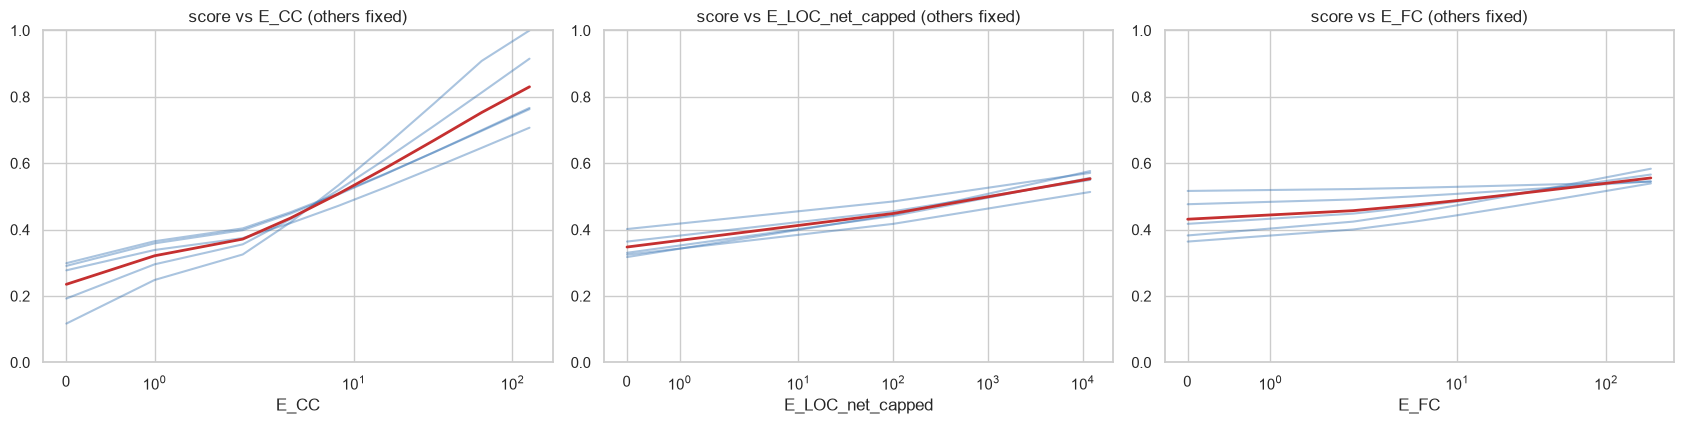

invariant 2 (never lowers the score): PASS


,folds_ok,worst_drop
feature,,
E_CC,5,0.0
E_FC,5,0.0
E_LOC_net_capped,5,0.0


In [4]:
base_row = {"E_CC": 8, "E_LOC_net_capped": 1500, "E_FC": 25, "E_CT": 2}
grid = {"E_CC": [0, 1, 2, 4, 8, 16, 32, 64, 128], "E_LOC_net_capped": [0, 100, 300, 800, 1500, 3000, 6000, 12000], "E_FC": [0, 2, 5, 10, 25, 50, 100, 200]}
mono = []
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for a, (feature, values) in zip(axes, grid.items()):
    rows = [{**base_row, feature: v} for v in values]
    mean, per_fold = score(rows)
    for o in range(per_fold.shape[0]):
        a.plot(values, per_fold[o], alpha=.4, color="#2b6cb0")
        mono.append({"feature": feature, "fold": list(fitted)[o], "non-decreasing": bool(np.all(np.diff(per_fold[o]) >= -1e-9)), "largest drop": float(np.min(np.diff(per_fold[o]), initial=0))})
    a.plot(values, mean, color="#c53030", lw=2)
    a.set(title=f"score vs {feature} (others fixed)", xscale="symlog", xlabel=feature, ylim=(0, 1))
plt.tight_layout()
plt.show()
mono = pd.DataFrame(mono)
mono_ok = bool(mono["non-decreasing"].all())
print("invariant 2 (never lowers the score):", "PASS" if mono_ok else "FAIL")
mono.groupby("feature").agg(folds_ok=("non-decreasing", "sum"), worst_drop=("largest drop", "min")).round(4)

## 3. Gaming cases

| Case | What it is |
|---|---|
| micro-commit spam | 200 one-line commits: lots of commits, almost no lines or files |
| library dump | one huge commit adding a library: very many files and lines (the per-commit line cap of 800 applies) |
| one huge commit | one commit with a real 800 capped lines and 40 files |
| many tiny real commits | 40 commits, 600 lines, 12 files |
| comment padding | like spam, with a few review comments (not applicable; reviews are not an input of the chosen features) |

In [5]:
cases = {
    "micro-commit spam": {"E_CC": 200, "E_LOC_net_capped": 200, "E_FC": 2, "E_CT": 0},
    "library dump": {"E_CC": 1, "E_LOC_net_capped": 800, "E_FC": 1000, "E_CT": 0},
    "one huge commit": {"E_CC": 1, "E_LOC_net_capped": 800, "E_FC": 40, "E_CT": 1},
    "many tiny real commits": {"E_CC": 40, "E_LOC_net_capped": 600, "E_FC": 12, "E_CT": 2},
    "typical active student": {"E_CC": 7, "E_LOC_net_capped": 1310, "E_FC": 21, "E_CT": 1},
    "heavy contributor": {"E_CC": 40, "E_LOC_net_capped": 6000, "E_FC": 120, "E_CT": 5},
}
rows = []
for name, row in cases.items():
    mean, per_fold = score([row])
    rows.append({"case": name, "mean score": float(mean[0]), "min over folds": float(per_fold.min()), "max over folds": float(per_fold.max()),
                 "ceiling 0.35": ("n/a" if name not in ("micro-commit spam", "library dump") else ("PASS" if per_fold.max() <= 0.35 else "FAIL"))})
gaming = pd.DataFrame(rows).set_index("case")
gaming.round(3)

,mean score,min over folds,max over folds,ceiling 0.35
case,,,,
micro-commit spam,0.783,0.635,1.000,FAIL
library dump,0.393,0.256,0.482,FAIL
one huge commit,0.318,0.239,0.365,n/a
many tiny real commits,0.660,0.564,0.801,n/a
typical active student,0.486,0.453,0.508,n/a
heavy contributor,0.762,0.684,0.854,n/a


In [6]:
spam_ok = gaming.loc[["micro-commit spam", "library dump"], "ceiling 0.35"].eq("PASS").all()
print("invariant 3 (spam and library dump at most 0.35):", "PASS" if spam_ok else "FAIL")
# the simple baseline for comparison
cc = lambda c: np.clip(np.log1p(c) / np.log1p(91), 0, 1)
print("commit count alone would give micro-commit spam:", round(float(cc(200)), 3), "| typical active student:", round(float(cc(7)), 3))

invariant 3 (spam and library dump at most 0.35): FAIL
commit count alone would give micro-commit spam: 1.0 | typical active student: 0.46


## 4. Sensitivity to the per-commit line cap

In [7]:
# E_LOC_net_capped caps each commit at 800 lines; how much does the score of a typical student depend on the lines input at all?
rows = [{"E_CC": 7, "E_LOC_net_capped": v, "E_FC": 21, "E_CT": 1} for v in (200, 500, 1000, 1500, 3000, 8000)]
mean, per_fold = score(rows)
pd.DataFrame({"lines": [r["E_LOC_net_capped"] for r in rows], "score": mean.round(3)}).set_index("lines").T

lines,200,500,1000,1500,3000,8000
score,0.445,0.465,0.48,0.489,0.504,0.526


## 5. Summary and log

In [8]:
summary = pd.DataFrame({"invariant": ["1. zero commits gives about 0", "2. more never lowers the score", "3. spam and library dump at most 0.35"],
                        "result": ["PASS" if zero_ok else "FAIL", "PASS" if mono_ok else "FAIL", "PASS" if spam_ok else "FAIL"]}).set_index("invariant")
log_run("07_robustness_and_gaming", f"{choice['model']} | {FS}", "invariants", {"zero_commits": zero_ok, "monotone": mono_ok, "spam_ceiling": bool(spam_ok)})
summary

,result
invariant,
1. zero commits gives about 0,FAIL
2. more never lowers the score,PASS
3. spam and library dump at most 0.35,FAIL


## 6. Reading the results

**Result: the chosen model fails two of the three invariants.**

| Invariant | Result |
|---|---|
| 1. Zero commits gives about 0 | **FAIL.** Folds B and C give 0.023 and 0.063 for a student with nothing. |
| 2. More commits, lines or files never lowers the score | **PASS** in all five folds. |
| 3. Spam and library dump at most 0.35 | **FAIL.** 200 one-line commits score **0.78** (0.64-1.00 across folds); a library dump of 1,000 files scores 0.39 (0.26-0.48). |

Other cases: one huge commit 0.32; many tiny real commits 0.66; typical active student 0.49; heavy contributor 0.76.

**Why it fails.** The model has no input that says *what* the commits contained. 200 commits look like a very active student, and the only
thing it sees besides the count is the capped line total. For comparison, commit count alone would give the spam case a **1.0**, so the
simple baseline is also easy to game; accuracy on honest students says nothing about robustness.

**What the protocol says.** "A model that breaks an invariant is rejected whatever its MAE." So the model chosen in notebook 05 is **rejected
as it stands**. This repeats the lesson of the earlier Effort work: a statistical model cannot guarantee physical rules (no commits means no
effort; a commit is not worth more than its content) on its own.

**The line cap helps only weakly.** The score of a typical student moves only from 0.45 to 0.53 as lines grow from 200 to 8,000.

**Next.** Notebook 07b adds a **deterministic guard layer** in front of the model (zero commits gives 0; commits and files are counted only
as far as the lines and file counts support them) and tests the invariants and the validation error again. This is recorded as an amendment
to the protocol, made after seeing these results but **before any test group is scored**.